,prompt,N,H,control_type,lam,n_inner,sample_mode,warmstart,drift_detach,r_unc,r_ctrl,delta_r,ctrl_energy,time_unc_s,time_ctrl_s
0,a sunset,10,4,fmrg,1.0,5,flow_map2,True,True,0.290388,0.290804,0.000416,0.088939,3.415727,64.519148
1,a sunset,10,4,fmrg,10.0,5,flow_map2,True,True,0.290388,0.294795,0.004407,0.090226,3.443402,65.348389
2,a sunset,10,4,fmrg,100.0,5,flow_map2,True,True,0.290388,0.315125,0.024737,0.208107,3.459335,65.475038
3,a sunset,10,4,fmrg,500.0,5,flow_map2,True,True,0.290388,0.354666,0.064278,1.572446,3.463030,65.554463
4,a sunset,10,4,fmrg,1000.0,5,flow_map2,True,True,0.290388,0.366251,0.075863,5.010071,3.466763,65.564731
5,a sunset,10,4,fmrg,2000.0,5,flow_map2,True,True,0.290388,0.382662,0.092274,14.313111,3.464780,65.589318
6,a sunset,10,4,fmrg,5000.0,5,flow_map2,True,True,0.290388,0.406621,0.116233,70.398338,3.464248,65.549391
7,a sunset,10,4,fmrg,10000.0,5,flow_map2,True,True,0.290388,0.395279,0.104891,179.979416,3.464058,65.604646
8,a sunset,10,4,fmrg,25000.0,5,flow_map2,True,True,0.290388,0.382559,0.092171,682.441040,3.464394,65.615779
9,a sunset,10,4,mpc,1.0,5,flow_map2,True,True,0.290388,0.291933,0.001545,0.501158,3.463150,64.020259


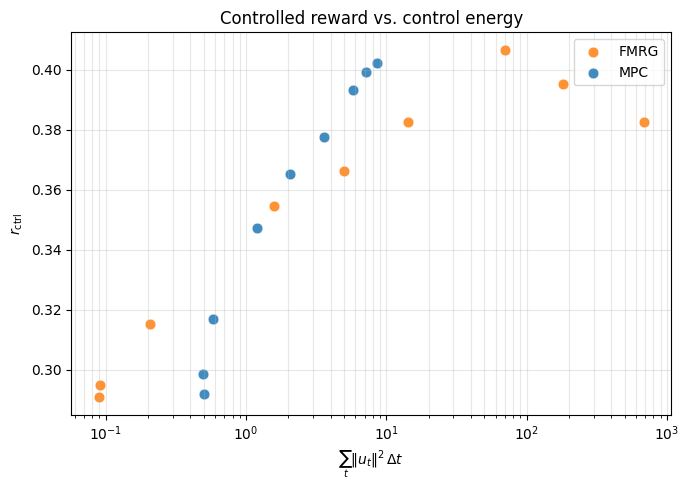

In [7]:
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv('results/summary.csv')
display(df)

fig, ax = plt.subplots(figsize=(7, 5))
colors = {"mpc": "tab:blue", "fmrg": "tab:orange"}

for control_type, sub in df.groupby("control_type"):
    ax.scatter(
        sub["ctrl_energy"], sub["r_ctrl"],
        label=control_type.upper(),
        color=colors.get(control_type, "gray"),
        s=60,
        alpha=0.85,
        edgecolors="white",
        linewidths=0.5,
    )

ax.set_xscale("log")
ax.set_xlabel(r"$\sum_t \|u_t\|^2\,\Delta t$")
ax.set_ylabel(r"$r_{\mathrm{ctrl}}$")
ax.set_title("Controlled reward vs. control energy")
ax.legend()
ax.grid(True, alpha=0.3, which="both")
plt.tight_layout()
plt.show()